# 19. Фотографии, лучи и камеры COLMAP

[План курса](../../README_ru.md)

Два снимка скульптуры похожи. На первом край каменного выступа закрывает кусок фона, на втором между ними уже видна щель. Этот маленький сдвиг позволяет восстановить глубину. Однотонное пятно на стене бесполезно, пока мы не можем уверенно опознать его же на втором кадре.


In [1]:
%matplotlib inline
from pathlib import Path
import sys
for folder in (Path.cwd(), *Path.cwd().parents):
    if (folder / "reconstruction.py").is_file():
        sys.path.insert(0, str(folder))
        break
import json
import numpy as np
import matplotlib.pyplot as plt
from reconstruction import *
from reconstruction_demos import photo_capture, tiles_figure, rays_figure, view_figure, error_figure, controls, damage
lang = 'ru'


## 1. Две камеры у стола

Начнём с почти игрушечной съёмки. Оптические оси параллельны, правая камера на 40 см правее левой. Между ними расстояние B, его называют базой. Оранжевый луч проходит через метку правого снимка, синий — левого. Оба лежат в одной горизонтальной плоскости. Маленькая ошибка в пикселях сбивает точку их встречи. На рисунке сверху глубина растёт от камер вверх.


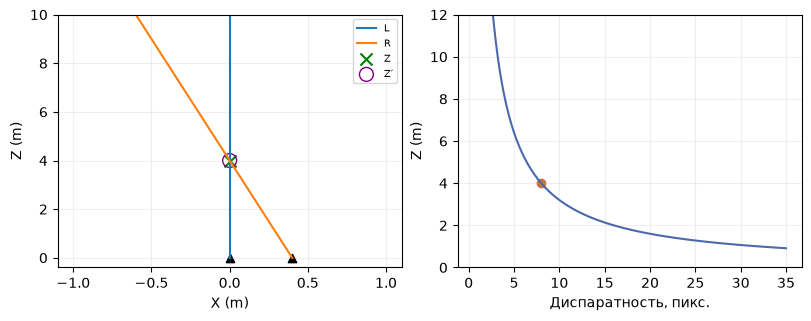

In [2]:
display(rays_figure(lang=lang)); plt.close()
controls(lambda B, du, Z: rays_figure(B, du, Z, lang),
         B=(0,1,.01,.4), du=(-4,4,.1,0), Z=(1,8,.1,4))


## 2. Из восьми пикселей получаются четыре метра

Пусть $X$ — смещение метки вправо от левой камеры в метрах, $Z$ — расстояние вперёд в метрах. $f$ измеряем уже в пикселях, это фокусное расстояние снимка. $c_x$ — горизонтальная координата главной точки. В правой камере то же место имеет координату $X-B$. Обозначим наблюдаемые столбцы через $u_L,u_R$.

$$
u_L=c_x+fX/Z,\qquad u_R=c_x+f(X-B)/Z.
$$

Вычитаем правый столбец из левого. Одинаковые $c_x$ сокращаются. В числителе остаётся $X-(X-B)=B$. Разность столбцов $d=u_L-u_R$ называется диспаратностью. Получается $d=fB/Z$. Чтобы выделить глубину, умножаем обе части на $Z$ и делим на $d$. Теперь $Z=fB/d$.

В нашем кадре $f=80$ пикселей, $B=0.4$ м, $X=0$, $c_x=40$, $Z=4$ м. Левый столбец 40, правый $40+80(0-0.4)/4=32$. Разность $40-32=8$ пикселей. Глубина $80\cdot0.4/8=4$ м: пиксели в числителе и знаменателе сокращаются. Если справа метка сдвинута на один пиксель вправо, то $d=7$, и глубина уже $32/7\approx4.57$ м. При $B=0$ оба луча выходят из одной точки и по одной метке глубину определить нельзя. При $d=0$ для ненулевой базы конечного пересечения здесь нет.

На прогулке вокруг объекта камеры повёрнуты. Тогда каждая метка задаёт луч из своего центра, в направлении, рассчитанном по своим параметрам камеры. Из-за шума лучи могут пройти мимо друг друга. Восстановление ищет такую 3D-точку, чьи **проекции** близки к наблюдаемым меткам на нескольких снимках.


In [3]:
for B, shift in [(.4,0), (.4,1), (.05,0), (.05,1)]:
    uL, uR = 40, 40-80*B/4+shift
    print(B, shift, "→", triangulate(80,B,uL,uR))
assert triangulate(80,.4,40,32) == 4


0.4 0 → 4.0
0.4 1 → 4.571428571428571
0.05 0 → 4.0
0.05 1 → None


## 3. Что попадает в съёмку

Камера перемещается небольшими шагами, пока в соседних кадрах остаются знакомые мелкие детали. Матовый неподвижный предмет, рассеянный свет и резкие кадры делают соответствия заметнее. Вторая дуга на другой высоте раскрывает верхнюю поверхность. При вращении на одном месте направление взгляда меняется, а центры камер почти совпадают. Лучи тогда плохо определяют глубину. При слишком большом шаге исчезают общие детали. Стекло, движущийся человек, повторяющийся орнамент и блик могут дать убедительную пару пикселей, относящихся к разным точкам мира.

Смаз стирает характерные углы. Автоэкспозиция способна сделать одну и ту же стену тёмной на первом кадре и светлой на следующем. Небольшая ошибка репроекции на видимых точках ничего не говорит про заднюю сторону, которой нет на снимках. До обучения полезнее всего увидеть сами кадры и положение камер.


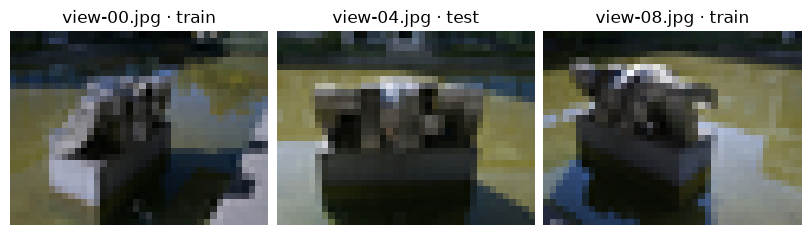

train: 8 test: 1


In [4]:
frames, seeds = photo_capture()
fig, axes = plt.subplots(1,3,figsize=(8,2.8),layout="constrained")
for ax, index in zip(axes,[0,4,8]):
    f=frames[index]
    ax.imshow(f["rgb"]); ax.set_title(f["name"]+" · "+f["split"]); ax.axis("off")
plt.show()
print("train:", sum(f["split"]=="train" for f in frames), "test:", sum(f["split"]=="test" for f in frames))


## 4. Что находится в разреженной модели

В курсе лежат девять небольших снимков реальной сцены **struktur28_auto** из PhysicalAI-NuRec-PPISP (NVIDIA Corporation, CC BY 4.0). Внешние и внутренние параметры уже известны. Облако состоит из точек, а не из граней. Точка может иметь трек: перечень кадров и номеров двумерных наблюдений, где её удалось опознать. Средний кадр view-04 оставим для проверки изображения. Положения камер предоставлены для всего набора, поэтому опыт проверяет синтез картинки при **известной камере**. Лицензия, преобразования и происхождение указаны в [описании фотографий](https://github.com/HeinrichWirth/gaussian-splatting-course/tree/main/data/photographic-example).

В текстовом экспорте COLMAP файл **cameras.txt** хранит модель объектива и её параметры. У PINHOLE это ширина, высота и $f_x,f_y,c_x,c_y$. В **images.txt** первая строка каждого кадра содержит кватернион $(w,x,y,z)$, сдвиг $t$, идентификатор камеры и имя файла. Следующая строка хранит тройки «пиксель x, пиксель y, ID 3D-точки». Значение −1 обозначает метку без восстановленной 3D-точки. Файл **points3D.txt** связывает ID с координатами, RGB, ошибкой и треком. Идентификатор 93 не означает 93-ю строку.

COLMAP записывает преобразование **из мира в камеру**: $p_c=R p_w+t$. У центра камеры собственная координата равна нулю. Подставляем $0=R C+t$, переносим $t$ и умножаем на обратный поворот. Получается $C=-R^T t$. При единичном повороте и $t=(-0.4,0,0)$ камера стоит в $(+0.4,0,0)$. Это источник частой ошибки знака. Для нашего рендерера сохраняются $C$ и поворот **из камеры в мир** $R^T$.

У COLMAP центр первого пикселя равен $(0.5,0.5)$, у нашего массива $(0,0)$. При уменьшении фотографии с 160 до 40 пикселей коэффициент ширины $s=40/160=0.25$. В фокусе $f'_x=s f_x$, а главная точка $c'_x=s c_x-0.5$. Для исходного $c_x=80$ получаем 19.5, середину между 19 и 20. По вертикали используется фактическое отношение высот после округления. Простое уменьшение картинки без изменения $f_x$ сдвинет предсказанные пиксели.


In [5]:
cam = frames[0]["camera"]
R = np.array(cam["rotation"]).T  # world to camera
C = np.array(cam["center"])
t = -R @ C
assert np.allclose(-R.T @ t, C)
print("C:", C.round(3), "f:", np.round(cam["focal"],3), "c:", cam["principal"])

# A measured feature and its projection in the original (160 x 120) training view.
from reconstruction_demos import ROOT
from geometry3d import project_point, quaternion_matrix
model_dir = ROOT / "data/photographic-example/sparse/0"
rows = [line for line in (model_dir/"images.txt").read_text().splitlines() if not line.startswith("#")]
header = rows[0].split()
observation = rows[1].split()
u, v, point_id = float(observation[0]), float(observation[1]), observation[2]
point_rows = (model_dir/"points3D.txt").read_text().splitlines()
point = next(line.split() for line in point_rows if line and line.split()[0] == point_id)
X = np.array(point[1:4],float)
world_to_cam = quaternion_matrix([float(v) for v in header[1:5]])
t0 = np.array(header[5:8],float)
intrinsics = next(line.split() for line in (model_dir/"cameras.txt").read_text().splitlines()
                  if line and not line.startswith("#"))
fx, fy, cx, cy = map(float,intrinsics[4:])
observed = np.array([u-.5,v-.5])
camera_point = world_to_cam @ X + t0
pred = project_point(camera_point,[fx,fy],[cx-.5,cy-.5])
wrong = project_point(camera_point+[.08,0,0],[fx,fy],[cx-.5,cy-.5])
print("point ID", point_id, "observed:", observed.round(3), "projected:", pred.round(3))
print("reprojection error (px):",round(np.linalg.norm(pred-observed),3),
      "after translation:",round(np.linalg.norm(wrong-observed),3))


C: [-0.528  0.407 -4.51 ] f: [42.363 42.705] c: [19.5, 14.5]
point ID 26 observed: [ 30.667 113.767] projected: [ 30.989 113.992]
reprojection error (px): 0.393 after translation: 4.012


## 5. Свои фотографии

В строках выше взята настоящая наблюдаемая метка на первом снимке. Её ID связывает две координаты на снимке с тремя координатами облака. Сначала вычисляется положение в камере, затем пиксель. Если намеренно прибавить 0.08 единицы сцены к горизонтальному смещению камеры в преобразовании, предсказание уходит от измерения. Последняя строка показывает обе длины ошибки в пикселях.

Для одной неподвижной сцены путь такой. Детектор находит метки. Сопоставление предлагает пары, геометрическая проверка отбрасывает несовместимые совпадения. Mapper регистрирует камеры, триангулирует точки и уточняет их вместе с камерами по ошибке репроекции. Под ошибкой здесь понимается длина вектора от наблюдаемого пикселя до предсказанного. Смещение на 3 пикселя вправо и 4 вниз даёт √(9+16) = 5 пикселей.

Ниже воспроизводимые команды для установленного COLMAP. В примере сырые фотографии лежат в capture/input, а пустые каталоги capture/sparse и capture/text уже созданы. `exhaustive_matcher` проверяет пары всех изображений и подходит небольшой серии. При нескольких компонентах номер 0 в примере заменяется на каталог связной модели с нужными видами.

```sh
colmap feature_extractor --database_path capture/database.db --image_path capture/input
colmap exhaustive_matcher --database_path capture/database.db
colmap mapper --database_path capture/database.db --image_path capture/input --output_path capture/sparse
colmap image_undistorter --image_path capture/input --input_path capture/sparse/0 --output_path capture/undistorted --output_type COLMAP
colmap model_converter --input_path capture/undistorted/sparse --output_path capture/text --output_type TXT
```

Теперь пути для учебного загрузчика — `capture/text` и `capture/undistorted/images`. Модель без дисторсии нужна потому, что наш объектив имеет только перспективное деление. Искажённая фотография и прямолинейная камера расходятся сильнее всего по краям. Большой набор можно уменьшить для опыта. Уменьшать изображение и пересчитывать камеру должен один загрузчик.

[Командная строка COLMAP](https://colmap.github.io/cli.html) · [Формат модели](https://colmap.github.io/format.html) · [Съёмка и восстановление](https://colmap.github.io/tutorial.html)

## Опыт

Два набора дают одинаковую среднюю ошибку репроекции. У первого камеры стоят почти на месте, у второго обходят предмет дугой. Одинаково ли хорошо определена глубина?

<details><summary>Разбор</summary>

Нет. У первого даже большое смещение точки вдоль луча почти не меняет её проекцию. Небольшая ошибка изображения совместима с большой неопределённостью по глубине. У второго пересекающиеся под разными углами лучи сильнее ограничивают положение. Полезно сравнить длины треков, взаимное положение камер и сами снимки.

</details>
